# Projeto 2 — Sprint 1 | Antes da intervenção

**Variável:** Tempo de carregamento (min)  
**Fonte:** Planilha 1 — 300 observações anteriores à intervenção.

Este notebook atende às Questões 2 a 6 das orientações da Sprint 1. Os dados originais foram mantidos sem alterações. Execute no Google Colab ou Jupyter com a planilha Excel na mesma pasta.

## 1. Bibliotecas e carregamento

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

ARQUIVO = "Planilha1_Tempo de carregamento de caminhões com grãos.xlsx"
COLUNA = "Tempo de carregamento (min)"
UNIDADE = "minutos"

df = pd.read_excel(ARQUIVO)
if COLUNA not in df.columns:
    raise ValueError(f"Coluna não encontrada. Colunas disponíveis: {df.columns.tolist()}")
dados = pd.to_numeric(df[COLUNA], errors="coerce").dropna()
if len(dados) != 300:
    print(f"Atenção: foram encontradas {len(dados)} observações válidas; a orientação prevê 300.")
display(df.head())
print("n =", len(dados))

,Tempo de carregamento (min)
0,31.4
1,36.1
2,32.8
3,28.6
4,33.3


n = 300


## Questão 2 — Histograma e boxplot

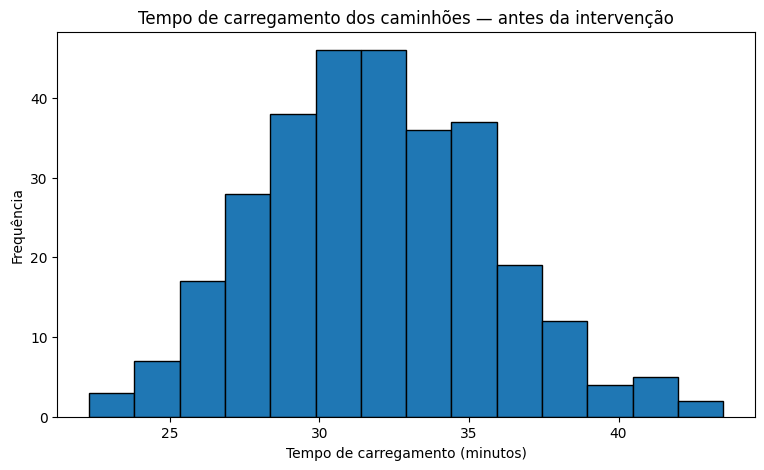

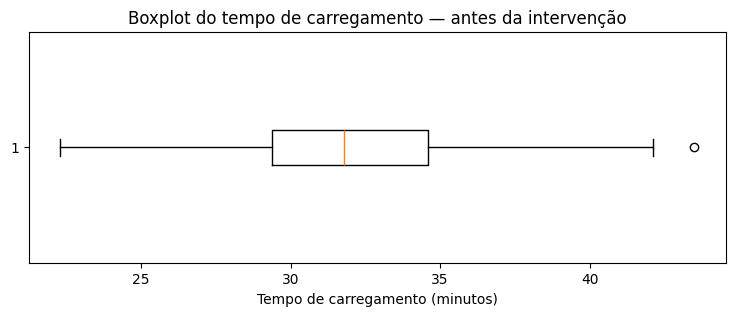

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(dados, bins="auto", edgecolor="black")
ax.set(title="Tempo de carregamento dos caminhões — antes da intervenção",
       xlabel="Tempo de carregamento (minutos)", ylabel="Frequência")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot(dados, vert=False)
ax.set(title="Boxplot do tempo de carregamento — antes da intervenção",
       xlabel="Tempo de carregamento (minutos)")
plt.show()

## Questão 3 — Média e desvio-padrão

In [ ]:
n = len(dados)
media = dados.mean()
dp = dados.std(ddof=1)
mediana = dados.median()
print(f"Média: {media:.4f} minutos")
print(f"Desvio-padrão amostral: {dp:.4f} minutos")
print(f"Mediana: {mediana:.4f} minutos")

Média: 31.8867 minutos
Desvio-padrão amostral: 3.8181 minutos
Mediana: 31.8000 minutos


## Questão 4 — Avaliação de compatibilidade com a distribuição normal

### 4a. Histograma, pico, média, mediana e regra empírica

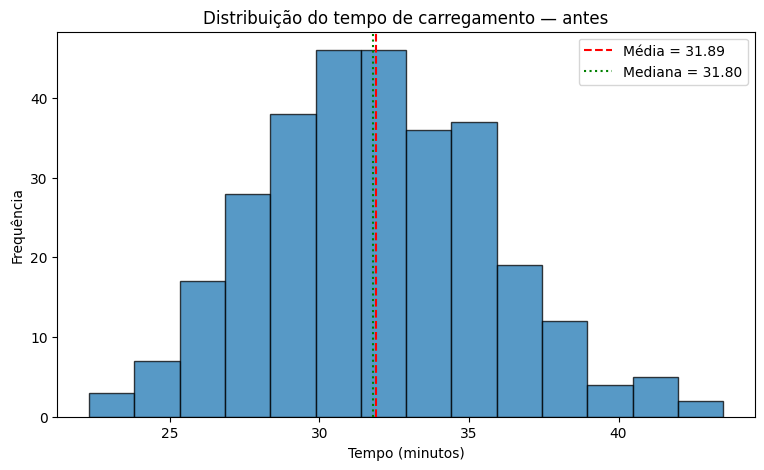

,Desvios-padrão,Limite inferior,Limite superior,Proporção observada,Referência normal
0,1,28.07,35.70,67.67%,68.27%
1,2,24.25,39.52,96.00%,95.45%
2,3,20.43,43.34,99.67%,99.73%


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(dados, bins="auto", edgecolor="black", alpha=0.75)
ax.axvline(media, color="red", linestyle="--", label=f"Média = {media:.2f}")
ax.axvline(mediana, color="green", linestyle=":", label=f"Mediana = {mediana:.2f}")
ax.set(title="Distribuição do tempo de carregamento — antes",
       xlabel="Tempo (minutos)", ylabel="Frequência")
ax.legend()
plt.show()

linhas = []
for k, alvo in [(1, .6827), (2, .9545), (3, .9973)]:
    prop = dados.between(media-k*dp, media+k*dp).mean()
    linhas.append([k, media-k*dp, media+k*dp, prop, alvo])
regra = pd.DataFrame(linhas, columns=["Desvios-padrão", "Limite inferior", "Limite superior",
                                      "Proporção observada", "Referência normal"])
display(regra.style.format({"Limite inferior":"{:.2f}", "Limite superior":"{:.2f}",
                            "Proporção observada":"{:.2%}", "Referência normal":"{:.2%}"}))

**Conclusão do item 4a:** O histograma apresenta um pico principal próximo da região central, e a média (31,89 min) e a mediana (31,80 min) são muito próximas. Pela regra empírica, 67,67% dos tempos estão entre média ± 1 desvio-padrão (referência: 68,27%); 96,00% estão entre média ± 2 desvios-padrão (referência: 95,45%); e 99,67% estão entre média ± 3 desvios-padrão (referência: 99,73%). Como as proporções observadas são muito próximas das referências, os resultados são compatíveis com uma distribuição aproximadamente normal.

### 4b. Simetria do boxplot — distâncias entre quartis

In [ ]:
q1, q2, q3 = dados.quantile([.25, .50, .75])
print(f"Q2 - Q1 = {q2-q1:.4f} minutos")
print(f"Q3 - Q2 = {q3-q2:.4f} minutos")
print(f"Q1={q1:.4f}; Q2 (mediana)={q2:.4f}; Q3={q3:.4f}")

Q2 - Q1 = 2.4250 minutos
Q3 - Q2 = 2.8000 minutos
Q1=29.3750; Q2 (mediana)=31.8000; Q3=34.6000


**Conclusão do item 4b:** O primeiro intervalo entre quartis mede Q2 − Q1 = 2,425 min, enquanto o segundo mede Q3 − Q2 = 2,800 min. As distâncias são próximas, embora não idênticas; isso indica uma região central aproximadamente simétrica, com leve diferença entre as metades inferior e superior. Portanto, o boxplot oferece evidência razoável de compatibilidade com a normalidade.

### 4c. Diagrama Q-Q

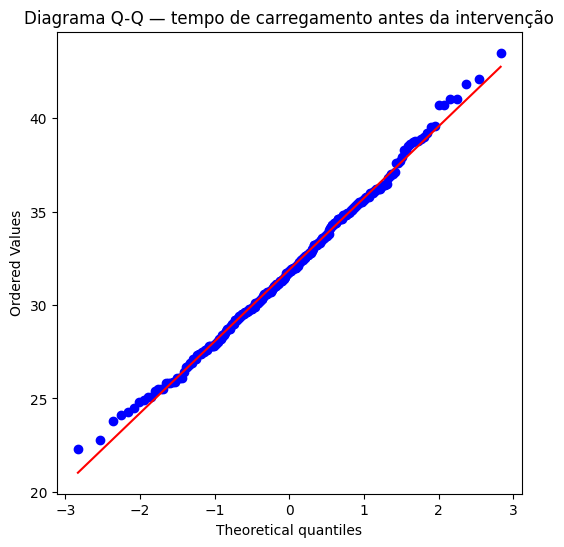

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(dados, dist="norm", plot=ax)
ax.set_title("Diagrama Q-Q — tempo de carregamento antes da intervenção")
plt.show()

**Conclusão do item 4c:** No diagrama Q-Q, os pontos acompanham muito de perto a reta de referência, sem curvaturas ou desvios sistemáticos importantes. Esse padrão indica que os quantis observados são próximos dos quantis esperados em uma distribuição normal, oferecendo forte evidência gráfica de compatibilidade com a normalidade.

## Questão 5 — Probabilidade no intervalo [a, b]

Para este notebook, foram informados os limites **a = 20 min** e **b = 43 min**. Eles serão tratados como valores de referência escolhidos pelo grupo para o processo. É importante que a Questão 1 explique de onde vêm esses limites (por exemplo, procedimento/indicador operacional da empresa) e que o grupo confirme a escolha com o docente, pois as planilhas e as orientações não estabelecem, por si só, uma faixa operacional oficial.

In [ ]:
# Valores de referência escolhidos pelo grupo (minutos)
a = 20
b = 43

if a > b:
    raise ValueError("O limite a deve ser menor ou igual a b.")

prob = stats.norm.cdf(b, loc=media, scale=dp) - stats.norm.cdf(a, loc=media, scale=dp)
print(f"P({a} <= X <= {b}) = {prob:.4%}")
print(f"Interpretação: no modelo normal ajustado aos dados anteriores, estima-se {prob:.2%} de probabilidade de um tempo de carregamento estar entre {a} e {b} minutos.")

P(20 <= X <= 43) = 99.7272%
Interpretação: no modelo normal ajustado aos dados anteriores, estima-se 99.73% de probabilidade de um tempo de carregamento estar entre 20 e 43 minutos.


## Questão 6 — Percentis 20 e 70

In [ ]:
p20 = stats.norm.ppf(.20, loc=media, scale=dp)
p70 = stats.norm.ppf(.70, loc=media, scale=dp)
print(f"Percentil 20 — limite máximo dos 20% menores tempos: {p20:.4f} minutos")
print(f"Percentil 70 — limite mínimo para os 30% maiores tempos: {p70:.4f} minutos")

Percentil 20 — limite máximo dos 20% menores tempos: 28.6733 minutos
Percentil 70 — limite mínimo para os 30% maiores tempos: 33.8889 minutos


**Interpretação:** Pelo modelo normal ajustado aos dados anteriores, o percentil 20 representa o tempo máximo aproximado dos 20% carregamentos mais rápidos. O percentil 70 representa o tempo mínimo aproximado a partir do qual estão os 30% carregamentos mais demorados. Os valores são estimativas do modelo normal, não limites operacionais definidos pela empresa.